# Questions 2.1 to 2.8

### Imports

In [41]:
import config as cfg
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import src.loading as ld
import src.normalise as norm
import src.features as ftrs
import src.outliers as outl

### Loading DataSet
No test actors included

In [42]:
df = ld.load_frames()
df.shape

(132176, 147)

## Q2.1

### Normalising DataSet

#### Using inter-ocular distance

In [43]:
df_d = norm.normalise_d(df)
df_d.shape

(132176, 147)

#### Sanity Check 

In [44]:
print("x_27 and y_27 == 0\n" if (df_d[["x_27", "y_27"]] == 0).all().all() else "Error: x_27 and y_27 != 0\n")

distance = ftrs.euclidean_distance(df_d, 36, 45)
if np.allclose(distance, 1):
    print("Distance between landmarks 36 and 45 are all 1\n")
else:
    print("Error: Distance between landmarks 36 and 45 are not all 1\n")

if np.isnan(df_d[norm.X_COLS + norm.Y_COLS]).any().any():
    print("Error: There are NaNs in the coordinates columns")
else:
    print("There are no NaNs in the coordinates columns")

x_27 and y_27 == 0

Distance between landmarks 36 and 45 are all 1

There are no NaNs in the coordinates columns


#### Using dimensions of the image

In [45]:
df_image = norm.normalise_image(df)
df_image.shape

(132176, 147)

#### Sanity Check

In [46]:
print("x_27 and y_27 == 0\n" if (df_image[["x_27", "y_27"]] == 0).all().all() else "Error: x_27 and y_27 != 0\n")

if np.isnan(df_image[norm.X_COLS + norm.Y_COLS]).any().any():
    print("Error: There are NaNs in the coordinates columns")
else:
    print("There are no NaNs in the coordinates columns")

x_27 and y_27 == 0

There are no NaNs in the coordinates columns


### Neutral Emotion

In [47]:
df_neutral = df[df["emotion"] == 1]
df_d_neutral = df_d[df_d["emotion"] == 1]
df_image_neutral = df_image[df_image["emotion"] == 1]

print(f"Number of unique videos in:\n df_neutral: {df_neutral['video_id'].nunique()}\n df_d_neutral: {df_d_neutral['video_id'].nunique()}\n df_image_neutral: {df_image_neutral['video_id'].nunique()}")

print(f"Number of unique actors in:\n df_neutral: {df_neutral['actor'].nunique()}\n df_d_neutral: {df_d_neutral['actor'].nunique()}\n df_image_neutral: {df_image_neutral['actor'].nunique()}")

Number of unique videos in:
 df_neutral: 80
 df_d_neutral: 80
 df_image_neutral: 80
Number of unique actors in:
 df_neutral: 20
 df_d_neutral: 20
 df_image_neutral: 20


#### Mouth width per frame

In [48]:
df_widths = pd.DataFrame({
    "actor": df_neutral["actor"],
    "raw": ftrs.euclidean_distance(df_neutral, 48, 54),
    "inter-ocular": ftrs.euclidean_distance(df_d_neutral, 48, 54),
    "image": ftrs.euclidean_distance(df_image_neutral, 48, 54),
})

df_widths

,actor,raw,inter-ocular,image
0,2,114.377139,0.568433,0.089487
1,2,114.784363,0.569890,0.089818
2,2,114.788240,0.569900,0.089827
3,2,114.780573,0.568761,0.089808
4,2,114.684437,0.568567,0.089740
...,...,...,...,...
8342,23,132.274903,0.640931,0.103634
8343,23,132.973982,0.643086,0.104179
8344,23,133.673071,0.647079,0.104724
8345,23,133.857910,0.647386,0.104843


#### Median of mouth width per actor

In [49]:
median_widths = df_widths.groupby("actor").median()
median_widths

,raw,inter-ocular,image
actor,,,
2,115.387954,0.566075,0.090233
3,124.821232,0.624451,0.097635
4,122.262218,0.611065,0.095907
5,139.316600,0.619302,0.108878
6,123.227310,0.615028,0.096501
7,133.503034,0.637391,0.104304
8,120.730195,0.613624,0.094383
9,122.382760,0.569194,0.095751
10,122.277430,0.591432,0.095975


#### Coeficient of Variation

In [50]:
cv = (median_widths.std() / median_widths.mean()).rename("CV").to_frame()
cv.index.name = "normalisation"
cv


,CV
normalisation,
raw,0.078814
inter-ocular,0.045567
image,0.078502


#### Plotting actors per normalisation

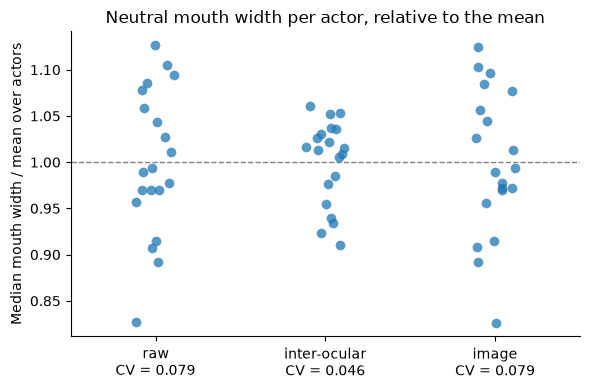

In [51]:
medians_rel = median_widths / median_widths.mean()

long = medians_rel.melt(var_name="normalisation", value_name="relative_width")

fig, ax = plt.subplots(figsize=(6, 4))
ax.axhline(1, color="grey", linestyle="--", linewidth=1, zorder=0)
sns.stripplot(data=long, x="normalisation", y="relative_width", jitter=0.12, size=7, alpha=0.75, color="tab:blue", ax=ax)
ax.set_xticks(range(len(cv)))
ax.set_xticklabels([f"{name}\nCV = {value:.3f}" for name, value in cv["CV"].items()])
ax.set_xlabel("")
ax.set_ylabel("Median mouth width / mean over actors")
ax.set_title("Neutral mouth width per actor, relative to the mean")
sns.despine(ax=ax)
plt.tight_layout()
plt.show()


The "raw" and "image" columns show the same spread, while the "inter-ocular" column shows a much tighter spread.

### Answer to Q2.1

## Normalisation

## Inter-ocular distance 
Leaves less variation between actors, the coefficient of variation of the 20 median neutral mouth widths is 0.046, against 0.079 for the normalisation by the image dimensions

The distance d is computed in each frame and scales with the apparent size of the face, so dividing by it expresses every coordinate in units of the inter-ocular distance.
Actors such as 5 and 11 have wide mouths in pixels but are close to the mean once divided by d. 
The variation that remains reflects real differences in facial proportions between people, which is good since it is what a normalisation should achieve.

## Image normalisation
Does not reduce the variation at all, its CV is practically the same as raw. 
The CV is a ratio of standard deviation to mean, so dividing every actor by the same constants leaves it unchanged.
The small difference comes only from x and y being divided by different constants.
Actors still differ in how large their face appears in the image, because of their distance to the camera and the size of their head.

Dividing x by 1280 and y by 720 also distorts the geometry of the face. The two axes are scaled by different factors, so the face is stretched vertically by 1280/720 ≈ 1.78 relative to its width. 
A distance then depends on its orientation, angles are not preserved, and tilting the head changes the measurements. The result also depends on the resolution of the camera.

> All the remaining tasks use the normalisation by d.


## Q 2.2.

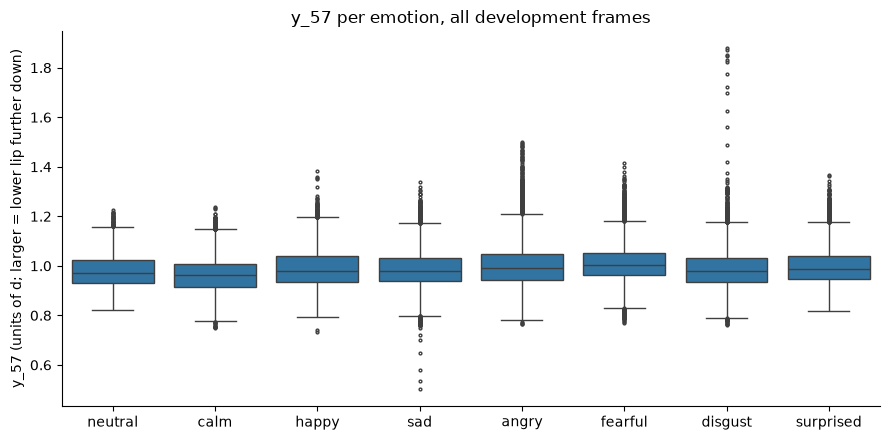

In [52]:
coord = "y_57"
order = list(cfg.EMOTIONS.values())
plot_df = df_d.assign(emotion_name=df_d["emotion"].map(cfg.EMOTIONS))

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=plot_df, x="emotion_name", y=coord, order=order,
            whis=1.5, fliersize=2, color="tab:blue", ax=ax)
ax.set_xlabel("")
ax.set_ylabel(f"{coord} (units of d; larger = lower lip further down)")
ax.set_title(f"{coord} per emotion, all development frames")
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

Box plot of `y_57` (lower edge of the lower lip, in units of d) per emotion, over all development frames. The whiskers follow Tukey's fences (1.5 IQR), so the points drawn beyond them are the frames that the IQR rule flags for this coordinate.

#### Outlier density per coordinate and emotion
Statistics (Q1, Q3, mean, std) computed within the frames of each emotion, one coordinate at a time.

In [53]:
coords = norm.X_COLS + norm.Y_COLS  # all 136 normalised coordinates

# same signature for the three rules, so the loop can call them the same way
rules = {
    "IQR": lambda X: outl.iqr_flags(X),
    "z (k=3)": lambda X: outl.zscore_flags(X, 3),
    "z (k=4)": lambda X: outl.zscore_flags(X, 4),
}

density = {}
for rule, flag in rules.items():
    rows = {}
    for code, name in cfg.EMOTIONS.items():
        X = df_d.loc[df_d["emotion"] == code, coords]  # frames of this emotion only
        rows[name] = 100 * flag(X).mean(axis=0) # ro for each coordinate
    table = pd.DataFrame(rows, index=coords).T # emotions x coordinates
    table["mean"] = table[coords].mean(axis=1)
    table["std"] = table[coords].std(axis=1, ddof=0)
    density[rule] = table

density["IQR"]

,x_0,x_1,x_2,x_3,x_4,x_5,x_6,x_7,x_8,x_9,...,y_60,y_61,y_62,y_63,y_64,y_65,y_66,y_67,mean,std
neutral,0.754762,1.162094,1.365760,1.030310,1.126153,1.701210,2.563795,1.785072,1.665269,1.497544,...,2.899245,0.047921,0.000000,0.000000,1.066251,0.503175,0.491194,0.479214,0.684378,0.866240
calm,10.957019,13.015244,13.945297,12.063178,11.116614,10.406692,9.399593,8.431016,7.594519,8.067800,...,1.474878,3.995377,3.857795,3.246932,3.131363,0.539321,0.654890,0.847504,3.933789,3.224660
happy,3.162329,3.583588,3.722084,3.295055,2.567950,2.567950,2.227480,1.887010,1.950488,2.088984,...,3.825956,2.862254,2.094754,2.227480,2.365976,0.600150,0.553985,0.496278,1.895115,1.170716
sad,3.103507,4.462002,4.962201,4.928096,4.030012,3.029614,2.978457,2.643097,2.603308,2.870460,...,1.665435,0.488831,0.528619,0.568408,1.131132,1.176604,1.284602,1.369863,1.611813,1.453254
angry,7.991326,7.828680,6.749797,6.267281,3.979398,3.502304,4.071564,4.342640,4.483600,4.906479,...,2.694497,1.442125,1.230686,1.474654,3.046896,3.052318,2.770398,2.737869,3.002687,1.757699
fearful,2.883192,2.628619,2.906873,3.623231,2.575336,3.640992,5.571014,6.725475,6.678113,6.589308,...,0.959091,0.384820,0.408502,0.449944,1.693209,2.439169,2.368125,2.456930,2.690651,1.937630
disgust,7.571230,6.728204,5.986554,4.940775,2.758510,2.038203,3.724256,5.212891,6.781560,6.109273,...,0.896382,0.288123,0.304130,0.320137,1.355245,0.805677,0.917725,1.035108,3.691104,3.163892
surprised,4.124145,3.085605,2.845480,2.413255,1.218634,1.338696,2.437267,2.977548,3.559851,3.896026,...,3.241686,1.050546,0.846440,1.314684,1.422740,1.692880,1.758915,1.927002,2.478892,1.931257


**Table: IQR (Tukey's fences, 1.5 IQR).** One row per emotion, one column per normalised coordinate: ρ is the percentage of the frames of that emotion outside the fences of that coordinate, with Q1 and Q3 computed within the emotion. `mean` and `std` summarise the 136 values of each row.

In [54]:
density["z (k=3)"]

,x_0,x_1,x_2,x_3,x_4,x_5,x_6,x_7,x_8,x_9,...,y_60,y_61,y_62,y_63,y_64,y_65,y_66,y_67,mean,std
neutral,0.503175,0.563077,0.599018,0.610998,0.646939,0.646939,0.599018,0.287528,0.251587,0.539116,...,0.047921,0.000000,0.000000,0.000000,0.083862,0.383371,0.323470,0.311489,0.234762,0.281326
calm,1.777558,1.540917,1.210720,0.919047,0.671399,0.544824,0.440262,0.330196,0.313687,0.341203,...,0.148588,0.088052,0.082549,0.154092,0.319190,0.209124,0.319190,0.357713,0.471906,0.445022
happy,1.281090,1.044492,1.015639,1.056033,1.079116,0.877142,0.917537,1.131052,1.217612,1.217612,...,0.409718,0.363552,0.380864,0.438571,0.525131,0.386635,0.328928,0.317387,0.799323,0.403569
sad,1.267550,1.216393,1.165236,0.773035,0.437674,0.335361,0.187575,0.136418,0.289888,0.579776,...,0.466094,0.238731,0.210311,0.278520,0.437674,0.761667,0.738930,0.790087,0.492174,0.443127
angry,2.401735,2.228246,1.507184,1.068040,1.105991,1.057197,1.127677,1.133098,1.100569,1.013825,...,0.899973,0.314448,0.287341,0.309027,0.986717,1.176471,1.187314,1.203578,0.944501,0.512917
fearful,1.302469,1.361672,1.278788,1.089338,0.965011,0.988692,1.071577,1.497839,1.450477,1.225505,...,0.343378,0.023681,0.124327,0.236813,0.905808,0.970931,0.882127,0.905808,0.790928,0.482635
disgust,1.488635,1.397930,1.163163,0.768328,0.517554,0.442856,0.640273,0.869704,1.061786,0.912389,...,0.250774,0.138726,0.149397,0.144061,0.282787,0.501547,0.464198,0.469534,0.826353,0.665144
surprised,1.722896,1.236643,0.942490,0.666347,0.060031,0.042022,0.720375,1.290671,1.290671,0.978509,...,0.204106,0.054028,0.072037,0.192100,0.408212,0.846440,0.852443,0.888462,0.718565,0.683060


**Table: z-score, k = 3.** Same layout; a frame is flagged when |z| > 3, with the mean and the standard deviation (ddof = 0) computed within the emotion.

In [55]:
density["z (k=4)"]

,x_0,x_1,x_2,x_3,x_4,x_5,x_6,x_7,x_8,x_9,...,y_60,y_61,y_62,y_63,y_64,y_65,y_66,y_67,mean,std
neutral,0.000000,0.000000,0.000000,0.035941,0.167725,0.191686,0.167725,0.023961,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.011980,0.011980,0.011980,0.005374,0.026544
calm,0.605360,0.302680,0.132079,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.005503,0.011007,0.000000,0.000000,0.016510,0.016510,0.037349,0.121622
happy,0.900225,0.755958,0.478966,0.363552,0.259680,0.259680,0.294304,0.519361,0.594379,0.600150,...,0.063477,0.046165,0.051936,0.051936,0.040395,0.046165,0.040395,0.040395,0.315096,0.294513
sad,0.574092,0.420622,0.045473,0.017052,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.193259,0.068209,0.045473,0.039789,0.062525,0.085261,0.107997,0.136418,0.082210,0.134510
angry,0.840336,0.477094,0.151803,0.086744,0.027108,0.124695,0.157224,0.097587,0.065058,0.037951,...,0.130117,0.086744,0.081323,0.092166,0.184332,0.346978,0.309027,0.330713,0.190511,0.210939
fearful,0.290095,0.236813,0.171689,0.065123,0.035522,0.047363,0.219052,0.307856,0.307856,0.230892,...,0.011841,0.011841,0.011841,0.011841,0.005920,0.189450,0.165769,0.201291,0.101472,0.106477
disgust,0.368157,0.272116,0.165404,0.149397,0.074699,0.064027,0.069363,0.101377,0.122719,0.117383,...,0.090705,0.096041,0.096041,0.096041,0.085370,0.213424,0.218760,0.218760,0.128408,0.076005
surprised,0.486253,0.264137,0.018009,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.006003,0.186097,0.168087,0.186097,0.135865,0.224530


**Table: z-score, k = 4.** Same layout; a frame is flagged when |z| > 4.

#### Summary: mean and std of ρ per emotion and rule

In [56]:
summary = pd.concat({rule: table[["mean", "std"]] for rule, table in density.items()}, axis=1)  # side by side
summary.round(2)

IQR       z (k=3)       z (k=4)      
           mean   std    mean   std    mean   std
neutral    0.68  0.87    0.23  0.28    0.01  0.03
calm       3.93  3.22    0.47  0.45    0.04  0.12
happy      1.90  1.17    0.80  0.40    0.32  0.29
sad        1.61  1.45    0.49  0.44    0.08  0.13
angry      3.00  1.76    0.94  0.51    0.19  0.21
fearful    2.69  1.94    0.79  0.48    0.10  0.11
disgust    3.69  3.16    0.83  0.67    0.13  0.08
surprised  2.48  1.93    0.72  0.68    0.14  0.22

**Table: summary.** The mean and std columns of the three tables above, side by side: for each emotion and rule, the mean and the standard deviation of ρ over the 136 coordinates, in %.

### Answer to Q2.2

The quartiles, the mean and the standard deviation are computed within the frames of each emotion, so ρ measures how many frames are atypical for that emotion, not how much the face moves in it.

In every emotion the IQR flags more frames than the z-score with k = 3, and k = 3 more than k = 4: the mean ρ ranges from 0.7 % to 3.9 % with the IQR, from 0.2 % to 0.9 % with k = 3 and from 0.01 % to 0.3 % with k = 4. This follows from how the rules are built: even for normal data without anomalies, Tukey's fences lie at about ±2.7σ and flag about 0.7 % of the values, against 0.27 % for |z| > 3 and 0.006 % for |z| > 4. Neutral is close to these references, while the other emotions are above them for all three rules, so extreme values are more frequent than in a normal distribution. The two rules also differ in robustness: the quartiles are not affected by the extreme values, while the mean and the standard deviation are pulled and inflated by them, so the z-score can hide the outliers it is looking for.

Between emotions, neutral has the lowest density for all three rules, and angry and disgust are always in the upper half. The ranking is not the same for every rule: calm has the highest mean ρ with the IQR (3.9 %) but is seventh of eight with both z-scores, so the rules do not always agree on which emotion has the most outliers. Finally, the standard deviation of ρ is of the same order as its mean, or larger, in every emotion and rule: the density depends strongly on the coordinate, and the mean over the 136 coordinates summarises it only roughly.
